# Multiple actions: detection with and without additional ambiguity cues
**Question:** How does the presence of additional ambiguity cues affect RoBERTa's detection of requirements annotated with multiple actions?

This Phase I analysis follows `model_plots.ipynb`, using saved test inputs, annotations and model outputs. It compares `multiple_actions` alone with the same annotation alongside additional reasons, then investigates controlled wording edits.

**Run:** use the project environment with dependencies from `training/requirements.txt`. Interactive views require a live notebook kernel. Keep `RUN_EDIT_INFERENCE = False` to analyze saved predictions; section 5 explains how to generate edit predictions when needed.


In [1]:
from pathlib import Path
import json
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import ipywidgets as widgets
from IPython.display import display, Markdown, HTML, clear_output

PROJECT_ROOT = None  # Set Path(...) only if this notebook is outside the repository.
ROOT = Path(PROJECT_ROOT) if PROJECT_ROOT else next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'results/roberta-pure-seed42/test_predictions.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the team repository or set PROJECT_ROOT.')
RESULTS = ROOT / 'results/roberta-pure-seed42'
pred = pd.read_csv(RESULTS / 'test_predictions.csv', keep_default_na=False)
threshold = json.loads((RESULTS / 'test_metrics.json').read_text())['threshold']
assert pred.instance_id.is_unique
assert pred.probability_ambiguous.between(0, 1).all()
assert (pred.predicted_label == (pred.probability_ambiguous >= threshold).astype(int)).all()
pred['reason_list'] = pred.reasons.apply(lambda x: sorted(set(r.strip() for r in x.split(',') if r.strip())))
ma = pred[pred.reason_list.apply(lambda x: 'multiple_actions' in x)].copy()
assert ma.true_label.eq(1).all(), 'Check the annotation assumptions before using miss rates.'
ALONE, COMBINED = 'Multiple actions only', 'With additional reasons'
ORDER = [ALONE, COMBINED]
COLORS = {ALONE: '#bc5090', COMBINED: '#007f86'}
ma['group'] = np.where(ma.reason_list.str.len().eq(1), ALONE, COMBINED)
ma['missed'] = ma.predicted_label.eq(0)
ma['outcome'] = np.where(ma.missed, 'Missed', 'Detected')
ma['words'] = ma.requirement_text.str.split().str.len()
ma['extra_reasons'] = ma.reason_list.apply(lambda rs: ', '.join(r for r in rs if r != 'multiple_actions'))
pio.templates.default = 'plotly_white'
pio.renderers.default = 'plotly_mimetype'
print(f'{len(ma)} multiple-action examples from {ma.source_file.nunique()} sources; threshold={threshold}.')


# Enable only in a live notebook frontend with working Jupyter widget support.
USE_WIDGETS = True


from contextlib import contextmanager
from IPython.utils.capture import capture_output

@contextmanager
def replace_widget_output(target):
    """Replace one panel atomically; do not accumulate captured kernel output."""
    with capture_output() as captured:
        yield
    content = [dict(output_type='display_data', data=item.data, metadata=item.metadata)
               for item in captured.outputs]
    for name, text in [('stdout', captured.stdout), ('stderr', captured.stderr)]:
        if text:
            content.append(dict(output_type='stream', name=name, text=text))
    target.outputs = tuple(content)

def dispose_previous_widgets(*names):
    """Detach callbacks and close the previous UI before rebuilding a cell."""
    seen = set()
    def close(widget):
        if not isinstance(widget, widgets.Widget) or id(widget) in seen:
            return
        seen.add(id(widget))
        for child in getattr(widget, 'children', ()):
            close(child)
        widget.unobserve_all()
        widget.close()
    for name in names:
        close(globals().pop(name, None))


import re
from difflib import SequenceMatcher

def highlighted_edit(original, edited):
    """Word/punctuation diff; escape dataset text before rendering HTML."""
    a = re.findall(r'\s+|\w+|[^\w\s]', str(original))
    b = re.findall(r'\s+|\w+|[^\w\s]', str(edited))
    left, right = [], []
    for tag, i, j, k, l in SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
        before, after = html.escape(''.join(a[i:j])), html.escape(''.join(b[k:l]))
        left.append(before if tag == 'equal' else '<del style="background:#ffe2e2;color:#7d1515">'+before+'</del>')
        right.append(after if tag == 'equal' else '<ins style="background:#d9f3e5;color:#125b35">'+after+'</ins>')
    return ('<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:16px">'
            '<div><b>Original — removed/replaced words</b><p style="white-space:pre-wrap;overflow-wrap:anywhere">'+''.join(left)+'</p></div>'
            '<div><b>Edited — added/replacement words</b><p style="white-space:pre-wrap;overflow-wrap:anywhere">'+''.join(right)+'</p></div></div>')


54 multiple-action examples from 11 sources; threshold=0.5.


## 1. Overall detection and scores
All examples here are annotated ambiguous. A **miss** is a prediction of unambiguous; the miss rate is the number missed divided by the number in that group. Model scores are not calibrated certainty.


In [2]:
def rate_table(frame, by):
    table = frame.groupby(by, observed=True).agg(n=('missed', 'size'), missed=('missed', 'sum')).reset_index()
    table['rate'] = table.missed / table.n
    z = 1.96
    denom = 1 + z*z / table.n
    center = (table.rate + z*z / (2*table.n)) / denom
    half = z * np.sqrt(table.rate*(1-table.rate)/table.n + z*z/(4*table.n**2)) / denom
    table['low'], table['high'] = (center-half).clip(0,1), (center+half).clip(0,1)
    table['minus'], table['plus'] = table.rate-table.low, table.high-table.rate
    table['count_label'] = table.missed.astype(str) + '/' + table.n.astype(str)
    return table

summary = rate_table(ma, 'group').set_index('group').loc[ORDER].reset_index()
observed = {r.group: (int(r.missed), int(r.n)) for r in summary.itertuples()}
print('Matches earlier 25/28 vs 0/26 observation:', observed == {ALONE:(25,28), COMBINED:(0,26)})
display(summary[['group','n','missed','rate','low','high']].round(3))

Matches earlier 25/28 vs 0/26 observation: True


,group,n,missed,rate,low,high
0,Multiple actions only,28,25,0.893,0.728,0.963
1,With additional reasons,26,0,0.000,0.000,0.129


### 1a. How often are ambiguous requirements missed?
Dots show miss rates; lines are approximate 95% Wilson intervals. Labels give the percentage and missed/total counts. Zero observed misses does not establish a zero population miss rate.


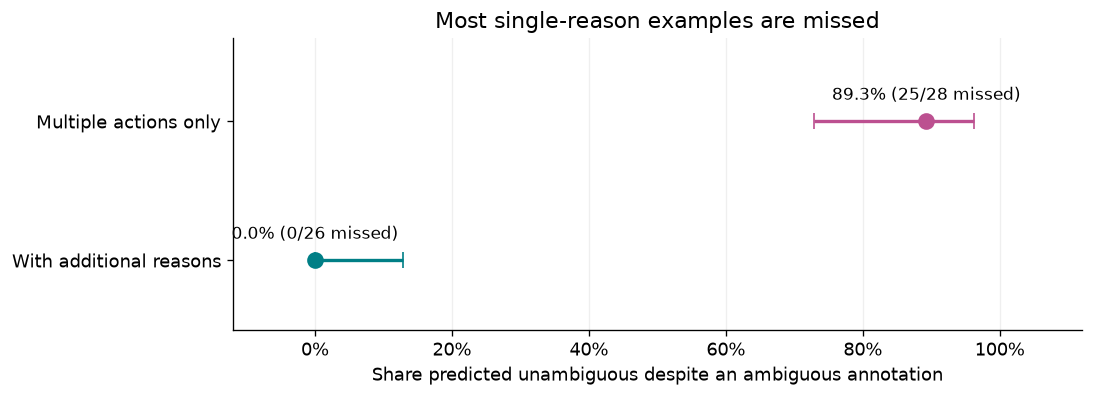

**Interpretation:** Multiple actions only: **25/28 missed (89.3%)**; With additional reasons: **0/26 missed (0.0%)**. The contrast motivates investigating wording and source differences.

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.2), layout='constrained')
for i, r in enumerate(summary.itertuples()):
    ax.errorbar(r.rate, i, xerr=[[max(0,r.minus)],[max(0,r.plus)]], fmt='o',
                color=COLORS[r.group], markersize=9, capsize=5, linewidth=2)
    ax.annotate(f'{r.rate:.1%} ({r.missed}/{r.n} missed)', (r.rate,i),
                xytext=(0,13), textcoords='offset points', ha='center', fontsize=10)
ax.set(yticks=range(2), yticklabels=ORDER, xlim=(-0.12,1.12), ylim=(-0.6,1.5),
       xlabel='Share predicted unambiguous despite an ambiguous annotation',
       title='Most single-reason examples are missed')
ax.invert_yaxis()
ax.set_xticks(np.linspace(0,1,6))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis='x', alpha=.2)
plt.show()
display(Markdown('**Interpretation:** ' + '; '.join(
    f'{r.group}: **{r.missed}/{r.n} missed ({r.rate:.1%})**' for r in summary.itertuples()) +
    '. The contrast motivates investigating wording and source differences.'))

### 1b. Are the decisions borderline or strongly scored?
Each dot is one requirement; dots below the decision threshold are misses. Boxes show the middle 50% and median; whiskers extend to observations within 1.5 interquartile ranges. Horizontal jitter separates overlapping points.


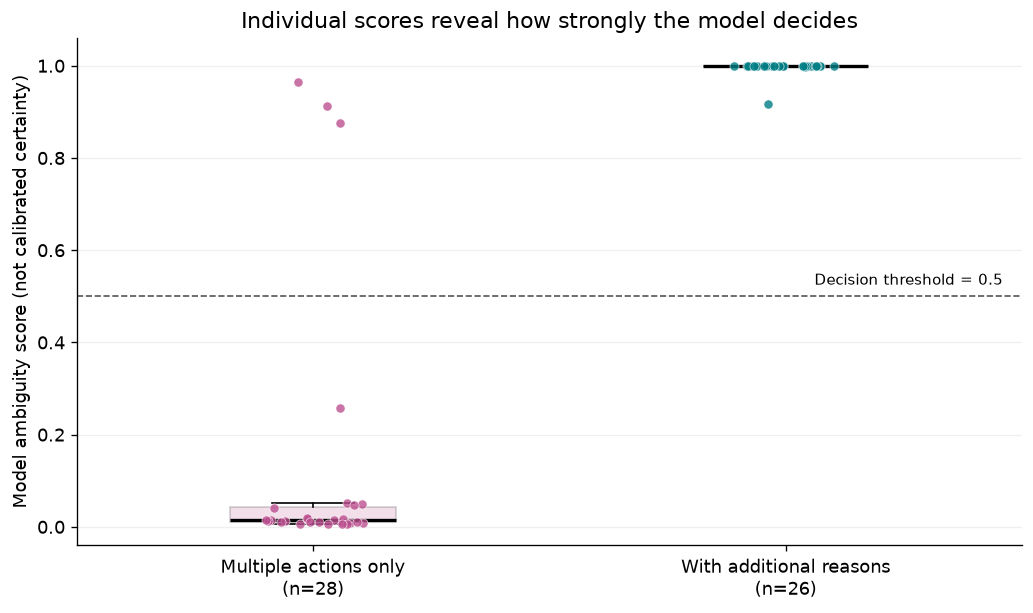

**Interpretation:** median scores are **0.015** for multiple actions alone and **1.000** with additional reasons. Misses near zero are strongly scored decisions, not borderline cases; inspect their wording in section 3.

In [4]:
fig, ax = plt.subplots(figsize=(8.5,5), layout='constrained')
rng = np.random.default_rng(42)
for i, group in enumerate(ORDER):
    values = ma.loc[ma.group.eq(group),'probability_ambiguous'].to_numpy()
    ax.boxplot([values], positions=[i], widths=.35, patch_artist=True, showfliers=False,
        boxprops=dict(facecolor=COLORS[group],alpha=.18), medianprops=dict(color='black',linewidth=2))
    ax.scatter(i+rng.uniform(-.11,.11,len(values)),values,s=30,color=COLORS[group],alpha=.8,
               edgecolors='white',linewidths=.4,zorder=3)
ax.axhline(threshold,color='#555555',linestyle='--',linewidth=1)
ax.text(.98,threshold+.025,f'Decision threshold = {threshold:g}',
        transform=ax.get_yaxis_transform(),ha='right',fontsize=9)
ax.set(xticks=[0,1],xticklabels=[f'{g}\n(n={sum(ma.group.eq(g))})' for g in ORDER],
       ylim=(-.04,1.06),ylabel='Model ambiguity score (not calibrated certainty)',
       title='Individual scores reveal how strongly the model decides')
ax.grid(axis='y',alpha=.2)
plt.show()
medians=ma.groupby('group').probability_ambiguous.median()
display(Markdown(f'**Interpretation:** median scores are **{medians[ALONE]:.3f}** for multiple actions alone '
    f'and **{medians[COMBINED]:.3f}** with additional reasons. Misses near zero are strongly scored decisions, '
    'not borderline cases; inspect their wording in section 3.'))

## 2. Source, length, and additional-reason comparisons
These comparisons examine possible explanations for the overall contrast. They describe naturally different groups rather than matched experimental conditions.


### 2a. Does the contrast appear within source documents?
Each source has separate points for the two annotation groups. Labels are missed/total; a dash marks an absent group, not zero misses.


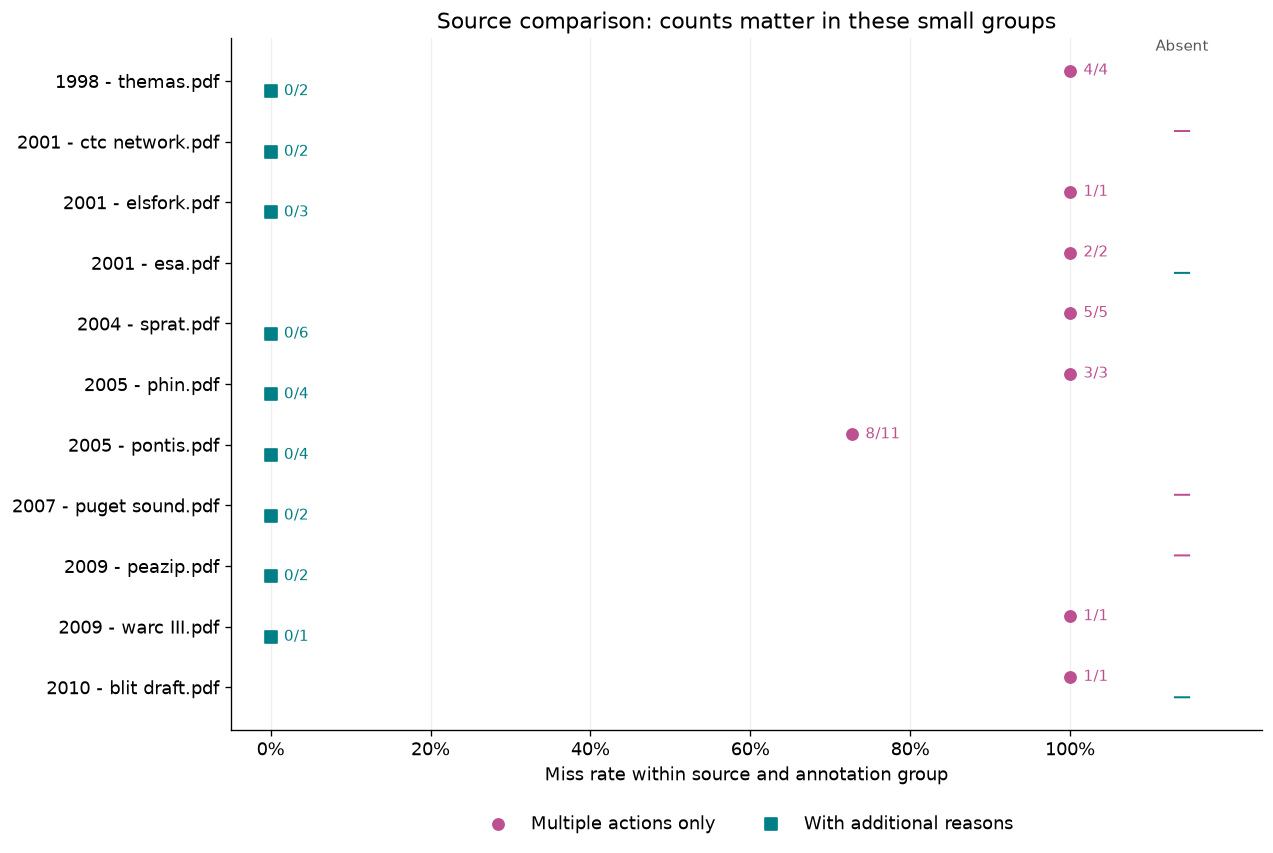

**Interpretation:** 6 sources contain both groups. Their pooled results are **22/25 misses (88.0%)** for multiple actions only; **0/20 misses (0.0%)** for with additional reasons. The contrast is not solely between different documents, but unequal source proportions and small groups prevent a matched comparison.

,group,n,missed,rate
0,Multiple actions only,25,22,0.88
1,With additional reasons,20,0,0.00


In [5]:
source_rates = rate_table(ma, ['source_file','group'])
sources = sorted(ma.source_file.unique())
fig, ax = plt.subplots(figsize=(10.5,7), layout='constrained')
for k,group in enumerate(ORDER):
    offset = -.17 if k==0 else .17
    for i,source in enumerate(sources):
        row=source_rates[source_rates.source_file.eq(source) & source_rates.group.eq(group)]
        if row.empty:
            ax.text(1.14,i+offset,'—',ha='center',va='center',color=COLORS[group])
            continue
        r=row.iloc[0]
        ax.scatter(r.rate,i+offset,color=COLORS[group],marker='o' if k==0 else 's',s=45,
                   label=group if source==sources[0] else None,zorder=3)
        ax.annotate(r.count_label,(r.rate,i+offset),xytext=(8,0),textcoords='offset points',
                    va='center',fontsize=9,color=COLORS[group])
ax.set(yticks=range(len(sources)),yticklabels=sources,ylim=(-.7,len(sources)-.3),
       xlim=(-.05,1.24),xlabel='Miss rate within source and annotation group',
       title='Source comparison: counts matter in these small groups')
ax.invert_yaxis()
ax.set_xticks(np.linspace(0,1,6))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.text(1.14,-.5,'Absent',ha='center',fontsize=9,color='#555555')
ax.grid(axis='x',alpha=.2)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.1),ncol=2,frameon=False)
plt.show()
shared_sources = ma.groupby('source_file').group.nunique().loc[lambda x:x == 2].index
shared_rates=rate_table(ma[ma.source_file.isin(shared_sources)],'group')
display(Markdown(f'**Interpretation:** {len(shared_sources)} sources contain both groups. Their pooled results are ' +
    '; '.join(f'**{r.missed}/{r.n} misses ({r.rate:.1%})** for {r.group.lower()}' for r in shared_rates.itertuples()) +
    '. The contrast is not solely between different documents, but unequal source proportions and small groups prevent a matched comparison.'))
display(shared_rates[['group','n','missed','rate']])

### 2b. Does the contrast remain for requirements of similar length?
Offset points compare the two groups within each word-count band. Labels are missed/total, with approximate 95% Wilson intervals; wider intervals indicate less precise estimates.


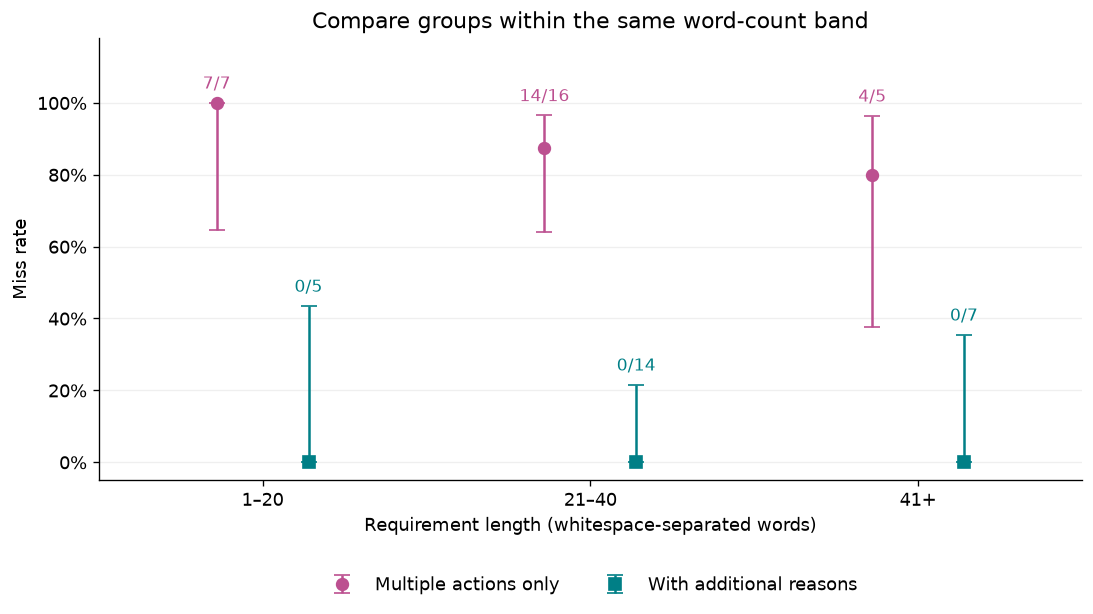

,length_band,group,n,missed,rate
0,1–20,Multiple actions only,7,7,1.000
1,1–20,With additional reasons,5,0,0.000
2,21–40,Multiple actions only,16,14,0.875
3,21–40,With additional reasons,14,0,0.000
4,41+,Multiple actions only,5,4,0.800
5,41+,With additional reasons,7,0,0.000


,count,median,min,max
group,,,,
Multiple actions only,28,26.5,16,51
With additional reasons,26,26.5,15,122


**Interpretation:** single-reason misses by length band: 1–20: **7/7**; 21–40: **14/16**; 41+: **4/5**. Combined-reason misses: 1–20: **0/5**; 21–40: **0/14**; 41+: **0/7**. Median lengths are **26.5 words** for multiple actions only; **26.5 words** for with additional reasons. Broad bands help check length differences but do not isolate their effect.

In [6]:
bands=['1–20','21–40','41+']
ma['length_band'] = pd.cut(ma.words,[0,20,40,np.inf],labels=bands)
length_rates = rate_table(ma,['length_band','group'])
fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
for k,group in enumerate(ORDER):
    rows=length_rates[length_rates.group.eq(group)]
    x=np.array([bands.index(str(b)) for b in rows.length_band])+(-.14 if k==0 else .14)
    ax.errorbar(x,rows.rate,yerr=np.maximum(0,np.array([rows.minus,rows.plus])),
                fmt='o' if k==0 else 's',color=COLORS[group],capsize=5,markersize=7,label=group)
    for xi,r in zip(x,rows.itertuples()):
        ax.text(xi,r.high+.04,r.count_label,ha='center',fontsize=10,color=COLORS[group])
ax.set(xticks=range(3),xticklabels=bands,ylim=(-.05,1.18),xlim=(-.5,2.5),
       xlabel='Requirement length (whitespace-separated words)',ylabel='Miss rate',
       title='Compare groups within the same word-count band')
ax.set_yticks(np.linspace(0,1,6))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis='y',alpha=.2)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.18),ncol=2,frameon=False)
plt.show()
display(length_rates[['length_band','group','n','missed','rate']].round(3))
word_summary=ma.groupby('group').words.agg(['count','median','min','max'])
display(word_summary)
display(Markdown('**Interpretation:** single-reason misses by length band: ' +
    '; '.join(f'{r.length_band}: **{r.missed}/{r.n}**' for r in length_rates[length_rates.group.eq(ALONE)].itertuples()) +
    '. Combined-reason misses: ' +
    '; '.join(f'{r.length_band}: **{r.missed}/{r.n}**' for r in length_rates[length_rates.group.eq(COMBINED)].itertuples()) +
    '. Median lengths are ' + '; '.join(f'**{word_summary.loc[g,"median"]:g} words** for {g.lower()}' for g in ORDER) +
    '. Broad bands help check length differences but do not isolate their effect.'))

### 2c. Do additional annotations have different score patterns?
Each row includes `multiple_actions` plus the named additional reason. Dots show individual scores; boxes show the middle 50% and median. The right panel zooms into the score range, which can exaggerate small differences. Categories overlap, so their counts cannot be added.


,additional_reason,n,missed,rate,low,high
0,missing_actor,1,0,0.0,0.0,0.793
1,undefined_quantity,1,0,0.0,0.0,0.793
2,undefined_term,2,0,0.0,0.0,0.658
3,vague_term,17,0,0.0,0.0,0.184
4,weak_modal,11,0,0.0,0.0,0.259


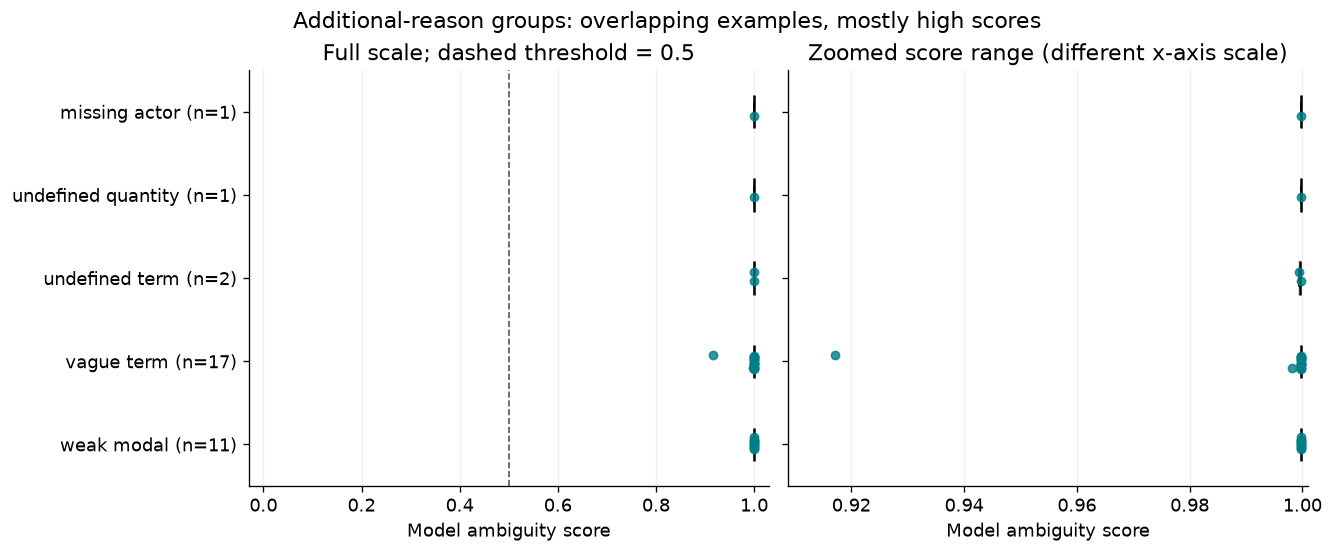

**Interpretation:** the lowest combined-group score is **0.917**. Compare the score spread and sample sizes rather than ranking extra reasons by small differences near one. These overlapping annotations do not establish which cue influenced the model.

In [7]:
extra = ma[ma.group.eq(COMBINED)].copy()
extra['additional_reason']=extra.reason_list.apply(lambda rs:[r for r in rs if r!='multiple_actions'])
extra=extra.explode('additional_reason')
extra_rates=rate_table(extra,'additional_reason')
display(extra_rates[['additional_reason','n','missed','rate','low','high']].round(3))
reasons=extra_rates.additional_reason.tolist()
fig,axes=plt.subplots(1,2,figsize=(11,4.5),sharey=True,layout='constrained')
rng=np.random.default_rng(21)
positions={r:rng.uniform(-.09,.09,len(extra[extra.additional_reason.eq(r)])) for r in reasons}
for ax in axes:
    for i,reason in enumerate(reasons):
        values=extra.loc[extra.additional_reason.eq(reason),'probability_ambiguous'].to_numpy()
        ax.boxplot([values],positions=[i],orientation='horizontal',widths=.4,showfliers=False,
            patch_artist=True,boxprops=dict(facecolor=COLORS[COMBINED],alpha=.16),
            medianprops=dict(color='black',linewidth=1.5))
        ax.scatter(values,i+positions[reason],s=24,color=COLORS[COMBINED],alpha=.8,zorder=3)
    ax.set_xlabel('Model ambiguity score')
    ax.grid(axis='x',alpha=.2)
axes[0].set_yticks(range(len(reasons)),[f'{r.replace("_"," ")} (n={sum(extra.additional_reason.eq(r))})' for r in reasons])
axes[0].invert_yaxis()
axes[0].set_xlim(-.03,1.03)
axes[0].axvline(threshold,color='#555555',linestyle='--',linewidth=1)
axes[0].set_title(f'Full scale; dashed threshold = {threshold:g}')
minimum=float(extra.probability_ambiguous.min())
axes[1].set_xlim(max(0,minimum-max(.002,(1-minimum)*.1)),1.001)
axes[1].set_title('Zoomed score range (different x-axis scale)')
fig.suptitle('Additional-reason groups: overlapping examples, mostly high scores',fontsize=13)
plt.show()
display(Markdown(f'**Interpretation:** the lowest combined-group score is **{minimum:.3f}**. '
    'Compare the score spread and sample sizes rather than ranking extra reasons by small differences near one. '
    'These overlapping annotations do not establish which cue influenced the model.'))

## 3. Explore requirements behind the patterns
Filter by source, annotation group, outcome, or length. Click a point or choose an ID to read its full text. **Explore Pontis** selects that source and resets the other filters, showing both groups.

The plot relates word count to ambiguity score; color identifies the annotation group and shape the prediction outcome. Points below the threshold are misses.

**Interpretation:** compare detected and missed examples within a source or similar length range. Inspect wording, missing context, and possible extraction or annotation problems. The displayed rates describe only the active selection: selecting only misses necessarily produces a 100% miss rate, not the source's overall error rate.


In [8]:
dispose_previous_widgets('explorer_ui', 'group_filter', 'source_filter', 'outcome_filter', 'length_filter', 'example_select', 'explorer_plot', 'explorer_text', 'figure_host', 'explorer_figure', 'pontis_button')
if USE_WIDGETS:
    group_filter = widgets.Dropdown(options=['All']+ORDER, description='Group:', layout=widgets.Layout(width='370px'))
    source_filter = widgets.Dropdown(options=['All']+sorted(ma.source_file.unique()), description='Source:', layout=widgets.Layout(width='370px'))
    outcome_filter = widgets.Dropdown(options=['All','Missed','Detected'], description='Outcome:')
    length_filter = widgets.IntRangeSlider(value=[int(ma.words.min()), int(ma.words.max())],
        min=int(ma.words.min()), max=int(ma.words.max()), description='Words:', continuous_update=False)
    example_select = widgets.Dropdown(description='Example:', layout=widgets.Layout(width='650px'))
    explorer_plot, explorer_text = widgets.Output(), widgets.Output()
    figure_host = widgets.VBox()
    explorer_figure = None
    pontis_sources = [s for s in ma.source_file.unique() if 'pontis' in s.casefold()]
    pontis_button = widgets.Button(description='Explore Pontis', icon='search', disabled=not pontis_sources)

    def select_score_point(trace, points, state):
        if points.point_inds:
            instance_id = str(trace.customdata[points.point_inds[0]][0])
            if instance_id in [value for _, value in example_select.options]:
                example_select.value = instance_id

    
    def show_example(change=None):
        with replace_widget_output(explorer_text):
            if not example_select.value:
                print('No examples match these filters.')
                return
            r = ma.set_index('instance_id').loc[example_select.value]
            display(HTML('<div style="padding:14px;border-left:4px solid #007f86;white-space:pre-wrap">'
                + html.escape(r.requirement_text) + '</div>'))
            print(f'Reasons: {r.reasons} | {r.outcome} | score={r.probability_ambiguous:.4f} | source={r.source_file}')
    
    def update_explorer(change=None):
        global explorer_figure
        figure_host.children = ()
        if explorer_figure is not None:
            explorer_figure.close()
            explorer_figure = None
        selected = ma[ma.words.between(*length_filter.value)]
        for field, control in [('group',group_filter),('source_file',source_filter),('outcome',outcome_filter)]:
            if control.value != 'All':
                selected = selected[selected[field].eq(control.value)]
        with replace_widget_output(explorer_plot):
            print(f'{len(selected)} examples selected; descriptive filtered view, not a new test set.')
            if len(selected):
                display(rate_table(selected,'group')[['group','n','missed','rate']])
                display(Markdown(f'**Current selection:** {int(selected.missed.sum())}/{len(selected)} examples are missed '
                    f'({selected.missed.mean():.1%}); median ambiguity score **{selected.probability_ambiguous.median():.3f}**. '
                    'These numbers describe only the active filters, not the full test set.'))
                fig = px.scatter(selected, x='words', y='probability_ambiguous', color='group', symbol='outcome',
                    color_discrete_map=COLORS, hover_name='instance_id', custom_data=['instance_id'], hover_data=['source_file','reasons'],
                    labels={'words':'Word count','probability_ambiguous':'Model ambiguity score'},
                    title='Click a point to read the requirement below')
                fig.add_hline(y=threshold,line_dash='dash')
                fig.update_layout(yaxis_range=[-0.03,1.03], height=400)
                explorer_figure = go.FigureWidget(fig)
                for trace in explorer_figure.data:
                    trace.on_click(select_score_point)
                figure_host.children = (explorer_figure,)
        # Changing options also changes value: render once, not from both paths.
        example_select.unobserve(show_example, names='value')
        try:
            example_select.options = [(f'{r.instance_id} | {r.outcome} | {r.extra_reasons or "no extra reason"}',r.instance_id)
                                      for r in selected.itertuples()]
        finally:
            example_select.observe(show_example, names='value')
        show_example()
    
    def explore_pontis(button=None):
        controls = [group_filter, source_filter, outcome_filter, length_filter]
        for control in controls:
            control.unobserve(update_explorer, names='value')
        try:
            group_filter.value = 'All'
            source_filter.value = pontis_sources[0]
            outcome_filter.value = 'All'
            length_filter.value = (int(ma.words.min()), int(ma.words.max()))
        finally:
            for control in controls:
                control.observe(update_explorer, names='value')
        update_explorer()

    pontis_button.on_click(explore_pontis)
    example_select.observe(show_example,names='value')
    for control in [group_filter,source_filter,outcome_filter,length_filter]:
        control.observe(update_explorer,names='value')
    explorer_ui = widgets.VBox([widgets.HBox([group_filter,source_filter]),widgets.HBox([outcome_filter,length_filter]),
                               pontis_button,explorer_plot,figure_host,example_select,explorer_text])
    display(explorer_ui)
    update_explorer()
else:
    # Edit these values and rerun this cell; no widgets are required.
    FILTER_GROUP = 'All'       # 'All', ALONE, or COMBINED
    FILTER_SOURCE = 'All'      # 'All' or an exact source_file from the table
    FILTER_OUTCOME = 'All'     # 'All', 'Missed', or 'Detected'
    EXAMPLE_ID = None          # None selects the first filtered example; otherwise 'PURE_...'
    selected = ma.copy()
    for field,value in [('group',FILTER_GROUP),('source_file',FILTER_SOURCE),('outcome',FILTER_OUTCOME)]:
        if value != 'All':
            selected = selected[selected[field].eq(value)]
    print(f'{len(selected)} examples match the filters.')
    if selected.empty:
        print('No matches. Change the filters above and rerun this cell.')
    else:
        display(rate_table(selected,'group')[['group','n','missed','rate']])
        fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
        for group in ORDER:
            rows=selected[selected.group.eq(group)]
            ax.scatter(rows.words,rows.probability_ambiguous,label=group,color=COLORS[group],alpha=.8)
        ax.axhline(threshold,color='grey',linestyle='--',label='Decision threshold')
        ax.set(xlabel='Word count',ylabel='Ambiguity score',ylim=(-.03,1.03),title='Filtered examples: length and model score')
        ax.legend(fontsize=9)
        plt.show()
        display(selected[['instance_id','source_file','group','outcome','words','probability_ambiguous']])
        chosen=selected.iloc[0] if EXAMPLE_ID is None else selected.set_index('instance_id').loc[EXAMPLE_ID]
        print('Selected example:',selected.iloc[0].instance_id if EXAMPLE_ID is None else EXAMPLE_ID)
        print('Full text:',chosen.requirement_text)
        print('Reasons:',chosen.reasons,'| Outcome:',chosen.outcome,'| Score:',round(chosen.probability_ambiguous,4))


## 4. Review the wording-edit pilot
Four originals were selected for editable modal or vague expressions, each with a **clarification** and a **control paraphrase**. Clarifications target an ambiguity cue; controls should preserve both meaning and ambiguity. Numerical limits are hypothetical, and changing should to shall changes obligation. Partial clarifications may remain ambiguous.

Use the selector to compare wording and review notes. Decisions are saved in `data/multiple_actions_edits.csv`, not through the selector: preserve IDs and originals, revise edits as needed, set `expected_label` to `0` (unambiguous), `1` (ambiguous), or `uncertain`, and record the rationale. Mark both members of a suitable pair `approved`; pending or rejected rows are excluded from inference.

**Interpretation:** this view documents experimental assumptions, not model behavior. AI-proposed labels require human review before inference; judge whether the intended change is valid without selecting edits based on favorable model outcomes.


In [9]:
dispose_previous_widgets('draft_ui', 'draft_select', 'draft_output')
EDIT_PATH = ROOT / 'data/multiple_actions_edits.csv'
edits = pd.read_csv(EDIT_PATH, keep_default_na=False, dtype=str)
def validate_edits(frame):
    required = {'edit_id','instance_id','original_text','edited_text','edit_type','purpose',
                'review_status','expected_label','review_notes'}
    assert required.issubset(frame.columns), 'Missing edit-table columns.'
    assert frame.edit_id.is_unique, 'Edit IDs must be unique.'
    assert frame.edit_type.isin(['clarification','control']).all()
    assert frame.review_status.isin(['pending','approved','rejected']).all()
    originals = ma.set_index('instance_id').requirement_text
    for r in frame.itertuples():
        assert r.instance_id in originals.index and r.original_text == originals.loc[r.instance_id], r.edit_id
        assert r.edited_text.strip() and r.edited_text != r.original_text, r.edit_id
    approved = frame[frame.review_status.eq('approved')]
    assert approved.expected_label.isin(['0','1','uncertain']).all(), 'Review expected labels first.'
    assert approved.review_notes.str.strip().ne('').all(), 'Document approval rationale.'
    for _, group in approved.groupby('instance_id'):
        assert len(group)==2 and set(group.edit_type)=={'clarification','control'}, 'Approve exactly one complete pair per original.'
    return approved

approved = validate_edits(edits)
display(edits[['edit_id','edit_type','purpose','review_status','expected_label']])
if USE_WIDGETS:
    draft_select = widgets.Dropdown(options=edits.edit_id.tolist(),description='Draft:', layout=widgets.Layout(width='650px'))
    draft_output = widgets.Output()
    def show_draft(change=None):
        r = edits.set_index('edit_id').loc[draft_select.value]
        with replace_widget_output(draft_output):
            for title, text in [('Original',r.original_text),('Draft edit',r.edited_text),('Review considerations',r.review_notes)]:
                display(HTML('<b>'+title+'</b><p style="white-space:pre-wrap">'+html.escape(text)+'</p>'))
            print('Status:',r.review_status,'| Expected label:',r.expected_label or 'not reviewed')
    draft_select.observe(show_draft,names='value')
    draft_ui = widgets.VBox([draft_select,draft_output])
    display(draft_ui)
    show_draft()
else:
    # Full texts remain readable in saved outputs without any widget renderer.
    for r in edits.itertuples():
        display(Markdown(f'**{r.edit_id} — {r.edit_type} ({r.review_status})**'))
        print('Original:',r.original_text)
        print('Draft edit:',r.edited_text)
        print('Purpose:',r.purpose)
        print('Review considerations:',r.review_notes)
        print('Expected label:',r.expected_label or 'not reviewed')
        print()
print(f'{len(approved)} approved edits. No inference has been requested.')


,edit_id,edit_type,purpose,review_status,expected_label
0,PURE_001238_clarification,clarification,Clarify message size and transmission delay wi...,approved,0
1,PURE_001238_control,control,Rephrase Data-wise as in data size while retai...,approved,1
2,PURE_003583_clarification,clarification,Change only should to shall to make the record...,approved,1
3,PURE_003583_control,control,Rephrase be able to record and store as be cap...,approved,1
4,PURE_003688_clarification,clarification,Change only should to shall; retain import/exp...,approved,1
5,PURE_003688_control,control,Rephrase import and export as importing and ex...,approved,1
6,PURE_005035_clarification,clarification,"Change only should to shall, retaining filteri...",approved,1
7,PURE_005035_control,control,Replace In addition to with Besides while reta...,approved,1


8 approved edits. No inference has been requested.


## 5. Optional frozen-model inference
After reviewing complete edit pairs, set `RUN_EDIT_INFERENCE = True` to generate predictions. The cell uses the saved model and preprocessing from `training/predict.py`, re-scores originals alongside edits, and reports differences from the saved test scores. Investigate large differences before interpreting the experiment.

Each run saves a new CSV under `results/roberta-pure-seed42/multiple_actions/`, including the reviewed texts, labels, notes, and model configuration. Existing test predictions are preserved. Leave inference disabled when analyzing an existing result.


In [10]:
RUN_EDIT_INFERENCE = False
MODEL_DIR = ROOT / 'models/roberta-pure-seed42'
new_result_path = None
if RUN_EDIT_INFERENCE:
    approved = validate_edits(pd.read_csv(EDIT_PATH,keep_default_na=False,dtype=str))
    if approved.empty:
        raise ValueError('No approved pairs. Review the CSV before enabling inference.')
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    from datetime import datetime, timezone
    import hashlib
    import uuid
    config = json.loads((MODEL_DIR / 'training_config.json').read_text(encoding='utf-8'))
    if config['threshold'] != threshold:
        raise ValueError('The model threshold differs from the saved test run.')
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR,local_files_only=True)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR,local_files_only=True)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device).eval()
    def score_texts(texts):
        scores, truncated = [], []
        for start in range(0,len(texts),config['eval_batch_size']):
            batch = texts[start:start+config['eval_batch_size']]
            truncated.extend(len(tokenizer(t,truncation=False,verbose=False)['input_ids']) > config['max_length'] for t in batch)
            encoded = tokenizer(batch,padding=True,truncation=True,max_length=config['max_length'],
                                pad_to_multiple_of=8,return_tensors='pt')
            with torch.inference_mode():
                logits = model(**{k:v.to(device) for k,v in encoded.items()}).logits
                scores.extend(torch.softmax(logits.float(),dim=-1)[:,1].cpu().tolist())
        return scores,truncated
    original_rows = approved.drop_duplicates('instance_id')
    orig_scores,orig_truncated = score_texts(original_rows.original_text.tolist())
    orig_map = dict(zip(original_rows.instance_id,orig_scores))
    trunc_map = dict(zip(original_rows.instance_id,orig_truncated))
    experiment = approved.copy()
    experiment['original_score'] = experiment.instance_id.map(orig_map)
    experiment['original_truncated'] = experiment.instance_id.map(trunc_map)
    experiment['edited_score'],experiment['edited_truncated'] = score_texts(experiment.edited_text.tolist())
    experiment['saved_test_score'] = experiment.instance_id.map(pred.set_index('instance_id').probability_ambiguous)
    experiment['threshold'] = config['threshold']
    experiment['model_dir'] = str(MODEL_DIR.relative_to(ROOT)) if MODEL_DIR.is_relative_to(ROOT) else str(MODEL_DIR)
    experiment['training_config'] = json.dumps(config,sort_keys=True)
    experiment['review_csv_sha256'] = hashlib.sha256(EDIT_PATH.read_bytes()).hexdigest()
    experiment['device'] = str(device)
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    experiment['created_utc'] = stamp
    output_dir = RESULTS / 'multiple_actions'
    output_dir.mkdir(exist_ok=True)
    new_result_path = output_dir / f'edits_{stamp}_{uuid.uuid4().hex[:6]}.csv'
    with new_result_path.open('x',encoding='utf-8',newline='') as handle:
        experiment.to_csv(handle,index=False)
    print('Saved:', new_result_path.relative_to(ROOT).as_posix())
    print('Maximum original-score difference from saved test:',
          (experiment.original_score-experiment.saved_test_score).abs().max())
    print('Inspect large differences before interpreting edits: verify the checkpoint and preprocessing.')
    del model
else:
    print('Inference disabled. No model loaded and no predictions generated.')


Inference disabled. No model loaded and no predictions generated.


## 6. Compare clarifications with controls
Leave `EDIT_RESULTS_PATH = None` to use the result just generated in this session, or supply a saved CSV's repository-relative path. The comparisons use that file's review snapshot.

**Interpretation:** compare each clarification with its control from the same original. A lower score or prediction flip is not automatically an improvement, particularly when ambiguity remains. Check expected labels and truncation flags; uncertain labels do not support correctness claims. Broad rewrites and one-word edits are different interventions.


,n,median_delta,flips,flip_rate,ambiguous_to_unambiguous,unambiguous_to_ambiguous
edit_type,,,,,,
clarification,4,-0.109901,1,0.25,1,0
control,4,0.000001,0,0.00,0,0


### Original versus edited scores
Each point is an edit: x = original score, y = edited score. Below the diagonal means a reduced ambiguity score. Circles identify clarifications and squares controls; labels give the shortened original ID and edit type. An asterisk marks a prediction flip. Leader lines separate labels for overlapping points without moving the data. Use the final selector for complete wording and reviewed labels.

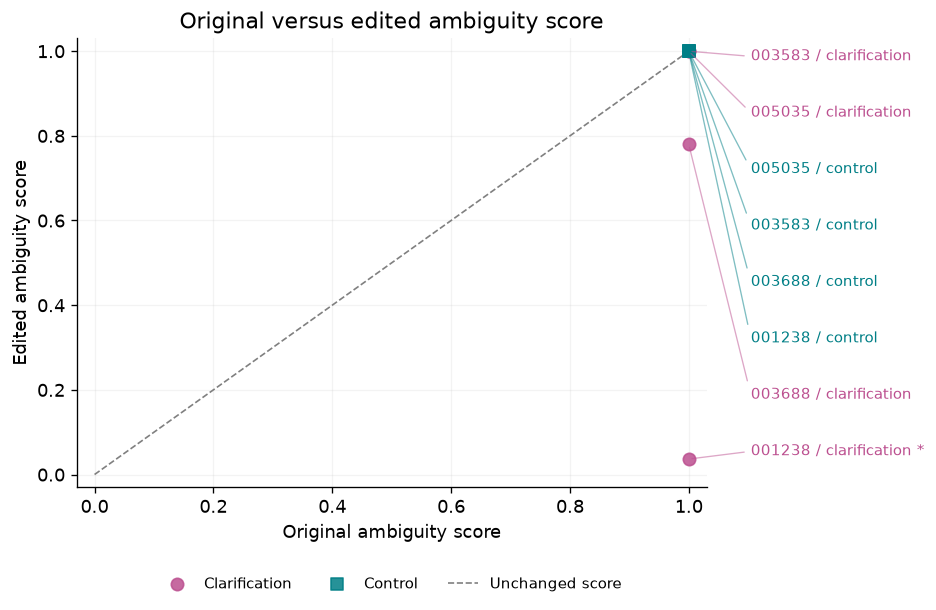

### Paired score changes: clarification versus control
Each row connects one original's clarification (circle) and control (square). Change = edited minus original score; left of zero means a reduction. A clarification further left than its control reduced the score more; nearby points indicate similar responses.

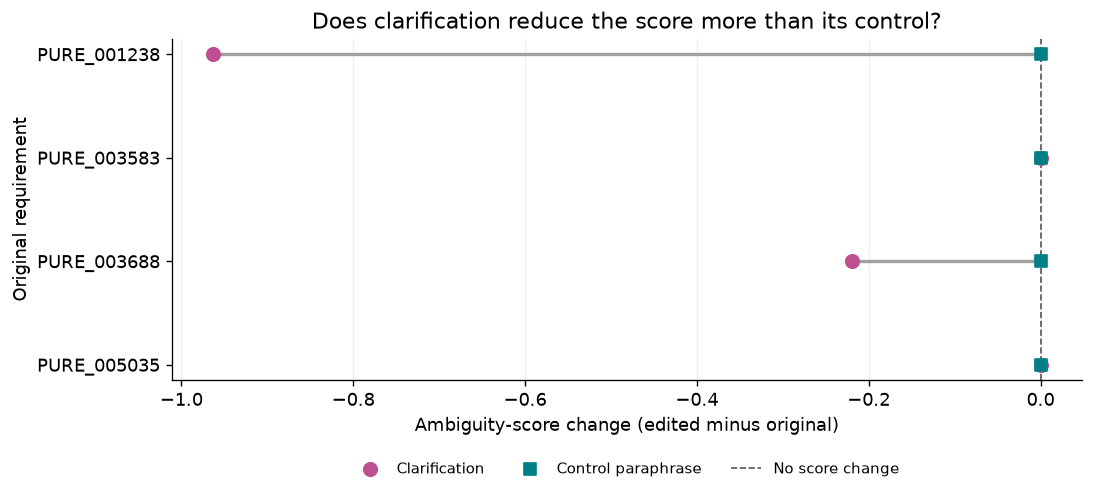

edit_type,clarification,control,clarification_minus_control
instance_id,,,
PURE_001238,-0.963080,6.192923e-05,-0.963142
PURE_003583,0.000032,1.668930e-06,0.000030
PURE_003688,-0.219819,-1.072884e-06,-0.219818
PURE_005035,0.000017,5.960464e-07,0.000016


**Paired contrast:** clarification score change minus control score change. Negative values mean clarification reduced the score more than its control.

**Interpretation:** clarification reduced the score more for **2/4 originals**; median paired contrast: **-0.110**. Inspect effect sizes and wording before treating small differences as meaningful.

### Inspect one original and its two edits
Select an original to compare highlighted edits, scores, and reviewed labels. Lines connect original and edited scores; crossing the threshold changes the prediction. Read the accompanying notes to assess whether each change resolves the intended issue.

In [11]:
dispose_previous_widgets('pair_ui', 'pair_select', 'pair_output')
EDIT_RESULTS_PATH = 'results/roberta-pure-seed42/multiple_actions/edits_20261108T173031308986Z_0b97d2.csv'  # Or paste 'results/roberta-pure-seed42/multiple_actions/edits_....csv'
result_path = Path(EDIT_RESULTS_PATH) if EDIT_RESULTS_PATH else new_result_path
if result_path is not None and not result_path.is_absolute():
    result_path = ROOT / result_path
paired = pd.DataFrame()
if result_path is None:
    print('No edit results selected. Review drafts, enable inference, then rerun this section.')
else:
    paired = pd.read_csv(result_path,keep_default_na=False)
    assert paired.review_status.eq('approved').all()
    assert paired[['original_score','edited_score']].apply(lambda x:x.between(0,1)).all().all()
    paired['delta'] = paired.edited_score-paired.original_score
    paired['original_prediction'] = (paired.original_score >= paired.threshold).astype(int)
    paired['edited_prediction'] = (paired.edited_score >= paired.threshold).astype(int)
    paired['flipped'] = paired.original_prediction.ne(paired.edited_prediction)
    paired['ambiguous_to_unambiguous'] = paired.original_prediction.eq(1) & paired.edited_prediction.eq(0)
    paired['unambiguous_to_ambiguous'] = paired.original_prediction.eq(0) & paired.edited_prediction.eq(1)
    display(paired.groupby('edit_type').agg(n=('edit_id','size'),median_delta=('delta','median'),
        flips=('flipped','sum'),flip_rate=('flipped','mean'),
        ambiguous_to_unambiguous=('ambiguous_to_unambiguous','sum'),
        unambiguous_to_ambiguous=('unambiguous_to_ambiguous','sum')))
    display(Markdown('### Original versus edited scores\n'
        'Each point is an edit: x = original score, y = edited score. Below the diagonal means a reduced ambiguity score. '
        'Circles identify clarifications and squares controls; labels give the shortened original ID and edit type. '
        'An asterisk marks a prediction flip. Leader lines separate labels for overlapping points without moving the data. '
        'Use the final selector for complete wording and reviewed labels.'))
    fig, ax = plt.subplots(figsize=(10, 5.5))
    fig.subplots_adjust(right=.65, bottom=.20)
    edit_colors = {'clarification':'#bc5090', 'control':'#007f86'}
    edit_markers = {'clarification':'o', 'control':'s'}
    for edit_type in ['clarification','control']:
        group = paired[paired.edit_type.eq(edit_type)]
        ax.scatter(group.original_score, group.edited_score, color=edit_colors[edit_type],
                   marker=edit_markers[edit_type], s=55, alpha=.85, label=edit_type.capitalize(), zorder=3)
    ax.plot([0,1],[0,1], color='grey', linestyle='--', linewidth=1, label='Unchanged score')
    label_rows = paired.sort_values(['edited_score','original_score','edit_id'])
    for label_y, r in zip(np.linspace(.08,.96,len(label_rows)), label_rows.itertuples()):
        short_id = str(r.instance_id).removeprefix('PURE_')
        text = f'{short_id} / {r.edit_type}' + (' *' if r.flipped else '')
        ax.annotate(text, xy=(r.original_score,r.edited_score), xycoords='data',
                    xytext=(1.07,label_y), textcoords='axes fraction', ha='left', va='center',
                    fontsize=9, color=edit_colors[r.edit_type], annotation_clip=False,
                    arrowprops=dict(arrowstyle='-',relpos=(0,.5),color=edit_colors[r.edit_type],alpha=.5,linewidth=.8))
    ax.set(xlim=(-.03,1.03),ylim=(-.03,1.03),xlabel='Original ambiguity score',
           ylabel='Edited ambiguity score',title='Original versus edited ambiguity score')
    ax.grid(alpha=.15)
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.17),ncol=3,frameon=False,fontsize=9)
    plt.show()

    display(Markdown('### Paired score changes: clarification versus control\n'
        'Each row connects one original\'s clarification (circle) and control (square). Change = edited minus original score; '
        'left of zero means a reduction. A clarification further left than its control reduced the score more; nearby points indicate similar responses.'))
    within = paired.pivot(index='instance_id',columns='edit_type',values='delta').reindex(
        columns=['clarification','control']).dropna()
    if len(within):
        fig, ax = plt.subplots(figsize=(9, max(3.5, .55*len(within)+1.8)), layout='constrained')
        y = np.arange(len(within))
        for yi, (_, row) in zip(y, within.iterrows()):
            ax.plot([row.clarification,row.control],[yi,yi],color='#a0a0a0',linewidth=2,zorder=1)
        ax.scatter(within.clarification,y,color='#bc5090',marker='o',s=65,label='Clarification',zorder=3)
        ax.scatter(within.control,y,color='#007f86',marker='s',s=45,label='Control paraphrase',zorder=4)
        ax.axvline(0,color='#555555',linestyle='--',linewidth=1,label='No score change')
        ax.set(yticks=y,yticklabels=within.index.tolist(),
               xlabel='Ambiguity-score change (edited minus original)',ylabel='Original requirement',
               title='Does clarification reduce the score more than its control?')
        ax.invert_yaxis()
        ax.grid(axis='x',alpha=.18)
        ax.legend(loc='upper center',bbox_to_anchor=(.5,-.2),ncol=3,frameon=False,fontsize=9)
        plt.show()
    else:
        print('No complete clarification/control pairs are available to plot.')
    within['clarification_minus_control'] = within.clarification-within.control
    display(within)
    display(Markdown('**Paired contrast:** clarification score change minus control score change. '
        'Negative values mean clarification reduced the score more than its control.'))
    if len(within):
        display(Markdown(f'**Interpretation:** clarification reduced the score more for '
            f'**{int(within.clarification_minus_control.lt(0).sum())}/{len(within)} originals**; '
            f'median paired contrast: **{within.clarification_minus_control.median():+.3f}**. '
            'Inspect effect sizes and wording before treating small differences as meaningful.'))
    display(Markdown('### Inspect one original and its two edits\n'
        'Select an original to compare highlighted edits, scores, and reviewed labels. Lines connect original and edited scores; '
        'crossing the threshold changes the prediction. Read the accompanying notes to assess whether each change resolves the intended issue.'))
    if not USE_WIDGETS:
        for r in paired.itertuples():
            print(r.edit_id, '|', r.edit_type, '| expected:', r.expected_label)
            print('Original:', r.original_text)
            print('Edited:', r.edited_text)
            print(f'Score: {r.original_score:.4f} -> {r.edited_score:.4f}; delta={r.delta:+.4f}')
    else:
        pair_select = widgets.Dropdown(options=paired.instance_id.unique().tolist(),description='Original:')
        pair_output = widgets.Output()
        def show_pair(change=None):
            rows = paired[paired.instance_id.eq(pair_select.value)]
            with replace_widget_output(pair_output):
                display(Markdown('Removed words are red and struck through; added words are green and underlined. These highlights show textual changes, not model attribution.'))
                fig = go.Figure()
                for r in rows.itertuples():
                    fig.add_trace(go.Scatter(x=['Original', 'Edited'],y=[r.original_score,r.edited_score],
                        mode='lines+markers',name=r.edit_type))
                    display(HTML('<h4>'+html.escape(r.edit_type.capitalize())+'</h4>' + highlighted_edit(r.original_text, r.edited_text)))
                    label_names = {0:'unambiguous', 1:'ambiguous'}
                    expected = {'0':'unambiguous', '1':'ambiguous', 'uncertain':'uncertain'}.get(str(r.expected_label),str(r.expected_label))
                    display(HTML('<p><b>Score:</b> '+f'{r.original_score:.4f} → {r.edited_score:.4f} (change {r.delta:+.4f})'
                        + '<br><b>Prediction:</b> '+label_names[r.original_prediction]+' → '+label_names[r.edited_prediction]
                        + '<br><b>Reviewed expected label:</b> '+html.escape(expected)
                        + '<br><b>Review status:</b> '+html.escape(str(r.review_status))
                        + '<br><b>Review notes:</b> '+html.escape(str(r.review_notes))+'</p>'))
                fig.add_hline(y=float(rows.iloc[0].threshold),line_dash='dash')
                fig.update_layout(yaxis_range=[-0.03,1.03],height=340,yaxis_title='Ambiguity score')
                fig.show()
        pair_select.observe(show_pair,names='value')
        pair_ui = widgets.VBox([pair_select,pair_output])
        display(pair_ui)
        show_pair()


## 7. Findings and limitations
The summary below combines the observed subgroup contrast with the available edit results.


In [12]:
for r in summary.itertuples():
    print(f'{r.group}: {r.missed}/{r.n} missed ({r.rate:.1%}); approximate 95% interval {r.low:.1%}–{r.high:.1%}.')
print('Shared-source subset:')
display(rate_table(ma[ma.source_file.isin(shared_sources)],'group')[['group','n','missed','rate']])
if paired.empty:
    print('Clarification sensitivity remains untested: no reviewed edit predictions were analyzed.')
else:
    print(f'Edit analysis covers {paired.instance_id.nunique()} reviewed originals; inspect controls before drawing conclusions.')


Multiple actions only: 25/28 missed (89.3%); approximate 95% interval 72.8%–96.3%.
With additional reasons: 0/26 missed (0.0%); approximate 95% interval 0.0%–12.9%.
Shared-source subset:


,group,n,missed,rate
0,Multiple actions only,25,22,0.88
1,With additional reasons,20,0,0.00


Edit analysis covers 4 reviewed originals; inspect controls before drawing conclusions.


**Finding:** detection differs sharply between the two annotation groups in this split, including comparisons within sources and length bands.

**Hypothesis:** additional wording cues may drive detection. Source style, co-annotations, extraction artifacts, and annotation disagreements remain alternative explanations; multiple actions are not inherently ambiguous.

**Limits:** groups are small, overlapping, and clustered by document. Wilson intervals do not account for source clustering. The four-original convenience pilot cannot establish general robustness. Findings are exploratory: further model tuning would require a separate untouched evaluation set.
